In [ ]:

# ============================================
# MILESTONE 3: EVALUATION METRICS
# Personalized TED Talks Recommendation System
# ============================================

# Import required libraries

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import joblib

from google.colab import drive
from sklearn.metrics.pairwise import cosine_similarity

# Mount Google Drive

drive.mount('/content/drive')

print("Libraries imported successfully!")
print("Google Drive mounted successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully!
Google Drive mounted successfully!


In [ ]:

# ============================================
# PROJECT PATHS
# ============================================

PROJECT_DIR = '/content/drive/MyDrive/TED_Talk_Recommendation'

ARTIFACT_DIR = os.path.join(PROJECT_DIR, 'model_artifacts')

# Existing model artifacts

MATRIX_PATH = os.path.join(ARTIFACT_DIR, 'tfidf_matrix.npz')
VECTORIZER_PATH = os.path.join(ARTIFACT_DIR, 'tfidf_vectorizer.joblib')
METADATA_PATH = os.path.join(ARTIFACT_DIR, 'talk_metadata.csv')
CONFIG_PATH = os.path.join(ARTIFACT_DIR, 'model_config.json')

# Evaluation output folder

EVALUATION_DIR = os.path.join(PROJECT_DIR, 'evaluation_results')
os.makedirs(EVALUATION_DIR, exist_ok=True)

print("Project paths configured.")

# Verify that all required files exist

required_files = [
    MATRIX_PATH,
    VECTORIZER_PATH,
    METADATA_PATH,
    CONFIG_PATH
]

for file_path in required_files:
    print(
        os.path.basename(file_path),
        ":", "Found" if os.path.exists(file_path) else "NOT FOUND"
    )


Project paths configured.
tfidf_matrix.npz : Found
tfidf_vectorizer.joblib : Found
talk_metadata.csv : Found
model_config.json : Found


In [ ]:

# ============================================
# LOAD EXISTING MODEL ARTIFACTS
# ============================================

# Load TF-IDF matrix
tfidf_matrix = sp.load_npz(MATRIX_PATH)

# Load trained TF-IDF vectorizer
tfidf_vectorizer = joblib.load(VECTORIZER_PATH)

# Load TED Talk metadata
metadata = pd.read_csv(METADATA_PATH)

# Load model configuration
with open(CONFIG_PATH, 'r') as file:
    model_config = json.load(file)

print("All model artifacts loaded successfully!")

print("\n--- MODEL INFORMATION ---")

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Metadata Shape:", metadata.shape)

print("Number of TED Talks:", len(metadata))
print("Number of TF-IDF Features:", tfidf_matrix.shape[1])

print("\n--- METADATA COLUMNS ---")
print(metadata.columns.tolist())

print("\n--- MODEL CONFIGURATION ---")
print(json.dumps(model_config, indent=4))


All model artifacts loaded successfully!

--- MODEL INFORMATION ---
TF-IDF Matrix Shape: (4005, 50000)
Metadata Shape: (4005, 5)
Number of TED Talks: 4005
Number of TF-IDF Features: 50000

--- METADATA COLUMNS ---
['title', 'speaker_1', 'topics', 'url', 'description']

--- MODEL CONFIGURATION ---
{
    "recommendation_method": "Content-based filtering",
    "vectorization": "TF-IDF",
    "similarity": "Cosine similarity",
    "max_features": 50000,
    "ngram_range": [
        1,
        2
    ],
    "min_df": 2,
    "stop_words": "english",
    "number_of_talks": 4005,
    "number_of_features": 50000
}


In [ ]:
print("--- DATA QUALITY CHECK ---")

print("\nMissing values:")
print(metadata.isnull().sum())

print("\nDuplicate titles:", metadata['title'].duplicated().sum())

print("\n--- SAMPLE TED TALKS ---")
display(metadata[['title', 'speaker_1', 'topics']].head(5))

print("\n--- TOPIC FORMAT ---")
print("Example topics:", metadata['topics'].iloc[0])
print("Topics data type:", type(metadata['topics'].iloc[0]))

print("\n--- TF-IDF MATRIX CHECK ---")
print("Matrix shape:", tfidf_matrix.shape)
print("Non-zero values:", tfidf_matrix.nnz)
print("Matrix sparsity:",
      round(1 - (tfidf_matrix.nnz /
                 (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])), 4))

row_norms = np.asarray(tfidf_matrix.multiply(tfidf_matrix).sum(axis=1)).flatten() ** 0.5

print("Zero-vector rows:", np.sum(row_norms == 0))
print("Minimum row norm:", round(row_norms.min(), 4))
print("Maximum row norm:", round(row_norms.max(), 4))

print("\n--- AVAILABLE ARTIFACTS ---")
for filename in sorted(os.listdir(ARTIFACT_DIR)):
    print(filename)

--- DATA QUALITY CHECK ---

Missing values:
title          0
speaker_1      0
topics         0
url            0
description    0
dtype: int64

Duplicate titles: 0

--- SAMPLE TED TALKS ---


,title,speaker_1,topics
0,averting the climate crisis,Al Gore,"['alternative energy', 'cars', 'climate change..."
1,the best stats you've ever seen,Hans Rosling,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,simplicity sells,David Pogue,"['computers', 'entertainment', 'interface desi..."
3,greening the ghetto,Majora Carter,"['MacArthur grant', 'activism', 'business', 'c..."
4,do schools kill creativity?,Sir Ken Robinson,"['children', 'creativity', 'culture', 'dance',..."



--- TOPIC FORMAT ---
Example topics: ['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainability', 'technology']
Topics data type: <class 'str'>

--- TF-IDF MATRIX CHECK ---
Matrix shape: (4005, 50000)
Non-zero values: 2245832
Matrix sparsity: 0.9888
Zero-vector rows: 0
Minimum row norm: 1.0
Maximum row norm: 1.0

--- AVAILABLE ARTIFACTS ---
evaluation_results.csv
model_comparison.csv
model_config.json
sample_recommendations.csv
similarity_scores.png
talk_metadata.csv
tfidf_matrix.npz
tfidf_vectorizer.joblib


In [ ]:
print("--- EXISTING EVALUATION RESULTS ---")

evaluation_df = pd.read_csv(
    os.path.join(ARTIFACT_DIR, 'evaluation_results.csv')
)

display(evaluation_df)

print("\n--- EXISTING MODEL COMPARISON ---")

comparison_df = pd.read_csv(
    os.path.join(ARTIFACT_DIR, 'model_comparison.csv')
)

display(comparison_df)

print("\n--- SAMPLE RECOMMENDATIONS ---")

recommendations_df = pd.read_csv(
    os.path.join(ARTIFACT_DIR, 'sample_recommendations.csv')
)

display(recommendations_df.head(10))

print("\n--- DATAFRAME INFORMATION ---")
print("Evaluation shape:", evaluation_df.shape)
print("Comparison shape:", comparison_df.shape)
print("Recommendations shape:", recommendations_df.shape)

--- EXISTING EVALUATION RESULTS ---


,Metric,Score
0,Precision@5,0.851685
1,Recall@5,0.004529
2,NDCG@5,0.856256
3,MAP@5,0.804432



--- EXISTING MODEL COMPARISON ---


,Model,Eligible queries,Precision@5,Recall@5,NDCG@5,MAP@5
0,Combined TF-IDF,801,0.851685,0.004529,0.856256,0.804432
1,Weighted TF-IDF,801,0.859426,0.004673,0.864697,0.814066



--- SAMPLE RECOMMENDATIONS ---


,input_talk,title,speaker_1,topics,url,similarity_score
0,Do schools kill creativity?,bring on the learning revolution!,Sir Ken Robinson,"['children', 'creativity', 'education', 'inven...",https://www.ted.com/talks/sir_ken_robinson_bri...,0.301597
1,Do schools kill creativity?,how to escape education's death valley,Sir Ken Robinson,"['culture', 'education', 'teaching', 'student']",https://www.ted.com/talks/sir_ken_robinson_how...,0.291415
2,Do schools kill creativity?,nerdcore comedy,Ze Frank,"['collaboration', 'comedy', 'community', 'cult...",https://www.ted.com/talks/ze_frank_nerdcore_co...,0.236661
3,Do schools kill creativity?,a one-man world summit,Rory Bremner,"['comedy', 'global issues', 'government', 'per...",https://www.ted.com/talks/rory_bremner_a_one_m...,0.228985
4,Do schools kill creativity?,how to run a company with (almost) no rules,Ricardo Semler,"['business', 'creativity', 'philosophy', 'work...",https://www.ted.com/talks/ricardo_semler_how_t...,0.222859
5,The best stats you've ever seen,let my dataset change your mindset,Hans Rosling,"['medicine', 'presentation', 'science', 'techn...",https://www.ted.com/talks/hans_rosling_let_my_...,0.511805
6,The best stats you've ever seen,new insights on poverty,Hans Rosling,"['Africa', 'Asia', 'Google', 'economics', 'glo...",https://www.ted.com/talks/hans_rosling_new_ins...,0.360768
7,The best stats you've ever seen,the good news of the decade? we're winning the...,Hans Rosling,"['Africa', 'TEDx', 'data', 'health', 'inequali...",https://www.ted.com/talks/hans_rosling_the_goo...,0.316988
8,The best stats you've ever seen,"global population growth, box by box",Hans Rosling,"['culture', 'data', 'demo', 'global issues', '...",https://www.ted.com/talks/hans_rosling_global_...,0.288569
9,The best stats you've ever seen,"insights on hiv, in stunning data visuals",Hans Rosling,"['AIDS', 'Africa', 'disease', 'global issues',...",https://www.ted.com/talks/hans_rosling_insight...,0.278242



--- DATAFRAME INFORMATION ---
Evaluation shape: (4, 2)
Comparison shape: (2, 6)
Recommendations shape: (10, 6)


In [ ]:
import ast

# Convert the topics column from strings into Python lists
metadata['topic_list'] = metadata['topics'].apply(ast.literal_eval)

# Check topic counts
metadata['topic_count'] = metadata['topic_list'].apply(len)

print("--- TOPIC STATISTICS ---")
print("Average topics per talk:", round(metadata['topic_count'].mean(), 2))
print("Minimum topics:", metadata['topic_count'].min())
print("Maximum topics:", metadata['topic_count'].max())

# Calculate how many talks share at least one topic
topic_sets = metadata['topic_list'].apply(set).tolist()

relevant_counts = []

for i, query_topics in enumerate(topic_sets):
    relevant_count = sum(
        1 for j, candidate_topics in enumerate(topic_sets)
        if i != j and query_topics.intersection(candidate_topics)
    )
    relevant_counts.append(relevant_count)

print("\n--- RELEVANCE DISTRIBUTION ---")
print("Average relevant talks per query:",
      round(np.mean(relevant_counts), 2))
print("Minimum relevant talks:",
      min(relevant_counts))
print("Maximum relevant talks:",
      max(relevant_counts))

print("\nPercentage of dataset considered relevant on average:",
      round(np.mean(relevant_counts) / (len(metadata) - 1) * 100, 2), "%")

--- TOPIC STATISTICS ---
Average topics per talk: 7.92
Minimum topics: 1
Maximum topics: 33

--- RELEVANCE DISTRIBUTION ---
Average relevant talks per query: 1400.67
Minimum relevant talks: 2
Maximum relevant talks: 2984

Percentage of dataset considered relevant on average: 34.98 %


In [ ]:
# Calculate relevance counts using two definitions

any_overlap_counts = []
strong_overlap_counts = []

for i, query_topics in enumerate(topic_sets):

    any_count = 0
    strong_count = 0

    for j, candidate_topics in enumerate(topic_sets):

        if i == j:
            continue

        shared_topics = len(query_topics.intersection(candidate_topics))

        if shared_topics >= 1:
            any_count += 1

        if shared_topics >= 2:
            strong_count += 1

    any_overlap_counts.append(any_count)
    strong_overlap_counts.append(strong_count)


relevance_comparison = pd.DataFrame({
    "Relevance Definition": [
        "At least 1 shared topic",
        "At least 2 shared topics"
    ],
    "Average Relevant Talks": [
        np.mean(any_overlap_counts),
        np.mean(strong_overlap_counts)
    ],
    "Minimum Relevant Talks": [
        np.min(any_overlap_counts),
        np.min(strong_overlap_counts)
    ],
    "Maximum Relevant Talks": [
        np.max(any_overlap_counts),
        np.max(strong_overlap_counts)
    ]
})

relevance_comparison["Average Relevant Percentage"] = (
    relevance_comparison["Average Relevant Talks"]
    / (len(metadata) - 1) * 100
)

display(relevance_comparison.round(2))

,Relevance Definition,Average Relevant Talks,Minimum Relevant Talks,Maximum Relevant Talks,Average Relevant Percentage
0,At least 1 shared topic,1400.67,2,2984,34.98
1,At least 2 shared topics,452.17,0,1772,11.29


In [ ]:
# Identify queries with at least two shared topics

eligible_queries = [
    i for i, count in enumerate(strong_overlap_counts)
    if count > 0
]

excluded_queries = [
    i for i, count in enumerate(strong_overlap_counts)
    if count == 0
]

print("--- EVALUATION QUERY ANALYSIS ---")

print("Total TED Talks:", len(metadata))
print("Eligible queries:", len(eligible_queries))
print("Excluded queries:", len(excluded_queries))

print(
    "Eligible query percentage:",
    round(len(eligible_queries) / len(metadata) * 100, 2),
    "%"
)

print("\n--- RELEVANT TALK DISTRIBUTION ---")

eligible_counts = [
    strong_overlap_counts[i] for i in eligible_queries
]

print("Average:", round(np.mean(eligible_counts), 2))
print("Median:", round(np.median(eligible_counts), 2))
print("25th percentile:", round(np.percentile(eligible_counts, 25), 2))
print("75th percentile:", round(np.percentile(eligible_counts, 75), 2))
print("Minimum:", min(eligible_counts))
print("Maximum:", max(eligible_counts))

--- EVALUATION QUERY ANALYSIS ---
Total TED Talks: 4005
Eligible queries: 3995
Excluded queries: 10
Eligible query percentage: 99.75 %

--- RELEVANT TALK DISTRIBUTION ---
Average: 453.31
Median: 406.0
25th percentile: 189.0
75th percentile: 661.0
Minimum: 1
Maximum: 1772


In [ ]:
print("--- EXISTING EVALUATION ARTIFACTS ---")

for filename in [
    "evaluation_results.csv",
    "model_comparison.csv",
    "sample_recommendations.csv"
]:
    path = os.path.join(ARTIFACT_DIR, filename)

    print(f"\n{filename}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

print("\n--- CURRENT QUERY COUNTS ---")
print("Total talks:", len(metadata))
print("Eligible under strict relevance:", len(eligible_queries))
print("Excluded:", len(excluded_queries))

--- EXISTING EVALUATION ARTIFACTS ---

evaluation_results.csv
Exists: True
Shape: (4, 2)
Columns: ['Metric', 'Score']

model_comparison.csv
Exists: True
Shape: (2, 6)
Columns: ['Model', 'Eligible queries', 'Precision@5', 'Recall@5', 'NDCG@5', 'MAP@5']

sample_recommendations.csv
Exists: True
Shape: (10, 6)
Columns: ['input_talk', 'title', 'speaker_1', 'topics', 'url', 'similarity_score']

--- CURRENT QUERY COUNTS ---
Total talks: 4005
Eligible under strict relevance: 3995
Excluded: 10


In [ ]:
from sklearn.model_selection import train_test_split

# Normalize topic names exactly as in the original notebook
metadata['topic_list'] = metadata['topics'].apply(
    lambda value: [
        str(topic).strip().lower()
        for topic in ast.literal_eval(value)
        if str(topic).strip()
    ]
)

# Reconstruct the original 80/20 split
all_indices = np.arange(len(metadata))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42
)

train_topic_sets = [
    set(metadata.iloc[i]['topic_list'])
    for i in train_indices
]

test_topic_sets = [
    set(metadata.iloc[i]['topic_list'])
    for i in test_indices
]

# Calculate relevance counts on the training candidates
any_overlap_counts = []
strong_overlap_counts = []

for query_topics in test_topic_sets:

    counts = [
        len(query_topics.intersection(candidate_topics))
        for candidate_topics in train_topic_sets
    ]

    any_overlap_counts.append(sum(count >= 1 for count in counts))
    strong_overlap_counts.append(sum(count >= 2 for count in counts))

print("--- ORIGINAL EVALUATION SPLIT ---")
print("Training talks:", len(train_indices))
print("Testing talks:", len(test_indices))

print("\n--- RELEVANCE ANALYSIS ON TEST QUERIES ---")
print("Any topic overlap - eligible queries:",
      sum(count > 0 for count in any_overlap_counts))

print("Two or more shared topics - eligible queries:",
      sum(count > 0 for count in strong_overlap_counts))

print("\nAverage relevant talks (1+ shared topic):",
      round(np.mean(any_overlap_counts), 2))

print("Average relevant talks (2+ shared topics):",
      round(np.mean(strong_overlap_counts), 2))

--- ORIGINAL EVALUATION SPLIT ---
Training talks: 3204
Testing talks: 801

--- RELEVANCE ANALYSIS ON TEST QUERIES ---
Any topic overlap - eligible queries: 801
Two or more shared topics - eligible queries: 799

Average relevant talks (1+ shared topic): 1125.49
Average relevant talks (2+ shared topics): 361.52


In [ ]:
DATA_PATH = os.path.join(PROJECT_DIR, 'ted_talks_cleaned.csv')

clean_df = pd.read_csv(DATA_PATH)

# Reproduce the original preprocessing
clean_df['title'] = clean_df['title'].fillna('').astype(str).str.strip()

clean_df['topic_list'] = clean_df['topics'].apply(
    lambda value: [
        str(topic).strip().lower()
        for topic in ast.literal_eval(str(value))
        if str(topic).strip()
    ]
)

clean_df['topics_text'] = clean_df['topic_list'].apply(
    lambda topics: ' '.join(topics)
)

for col in ['description', 'transcript']:
    clean_df[col] = clean_df[col].fillna('').astype(str)

text_columns = ['title', 'topics_text', 'description', 'transcript']

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .str.lower()
        .str.replace(r'<[^>]+>', ' ', regex=True)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

clean_df['combined_text'] = clean_df[text_columns].agg(' '.join, axis=1)
clean_df = clean_df.reset_index(drop=True)

print("--- DATASET ALIGNMENT CHECK ---")
print("Cleaned dataset shape:", clean_df.shape)
print("Metadata shape:", metadata.shape)

print("Same number of rows:", len(clean_df) == len(metadata))
print(
    "Titles match in the same order:",
    clean_df['title'].equals(metadata['title'])
)

print("\nText columns:", text_columns)
print("Missing transcript values:", clean_df['transcript'].isna().sum())

--- DATASET ALIGNMENT CHECK ---
Cleaned dataset shape: (4005, 24)
Metadata shape: (4005, 7)
Same number of rows: True
Titles match in the same order: True

Text columns: ['title', 'topics_text', 'description', 'transcript']
Missing transcript values: 0


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    clean_df,
    test_size=0.2,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("--- TRAIN/TEST SPLIT ---")
print("Training talks:", len(train_df))
print("Testing talks:", len(test_df))

print("\nTraining data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nFirst 3 test talks:")
display(test_df[['title', 'topic_list']].head(3))

--- TRAIN/TEST SPLIT ---
Training talks: 3204
Testing talks: 801

Training data shape: (3204, 24)
Testing data shape: (801, 24)

First 3 test talks:


,title,topic_list
0,glorious visions in animation and performance,"[art, design, performance, technology, animation]"
1,medicine for the 99 percent,"[tedx, economics, global issues, health]"
2,what is so special about the human brain?,"[brazil, brain, evolution, neuroscience]"


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2
)

X_train = vectorizer.fit_transform(train_df['combined_text'])
X_test = vectorizer.transform(test_df['combined_text'])

print("Training TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training TF-IDF shape: (3204, 50000)
Testing TF-IDF shape: (801, 50000)
Vocabulary size: 50000


In [ ]:
similarity_matrix = cosine_similarity(X_test, X_train)

print("Similarity matrix shape:", similarity_matrix.shape)
print("Minimum similarity:", similarity_matrix.min())
print("Maximum similarity:", similarity_matrix.max())
print("Average similarity:", similarity_matrix.mean())

Similarity matrix shape: (801, 3204)
Minimum similarity: 0.0
Maximum similarity: 0.9807679040960725
Average similarity: 0.04218238697225813


In [ ]:
def calculate_relevance(test_topics, train_topics):
    test_set = set(test_topics)
    return np.array([
        len(test_set.intersection(set(topics))) >= 2
        for topics in train_topics
    ])

train_topics = train_df['topic_list'].tolist()
test_topics = test_df['topic_list'].tolist()

relevance_matrix = np.array([
    calculate_relevance(topics, train_topics)
    for topics in test_topics
])

eligible_queries = relevance_matrix.sum(axis=1) > 0

print("Relevance matrix shape:", relevance_matrix.shape)
print("Eligible test queries:", eligible_queries.sum())
print("Excluded test queries:", (~eligible_queries).sum())
print("Average relevant talks:", relevance_matrix.sum(axis=1)[eligible_queries].mean())

Relevance matrix shape: (801, 3204)
Eligible test queries: 799
Excluded test queries: 2
Average relevant talks: 362.4205256570713


In [ ]:
def precision_at_k(relevance, k=5):
    return np.sum(relevance[:k]) / k

def recall_at_k(relevance, total_relevant, k=5):
    return np.sum(relevance[:k]) / total_relevant

def ndcg_at_k(relevance, total_relevant, k=5):
    relevance = np.asarray(relevance[:k], dtype=float)

    # Actual DCG based on recommended ranking
    discounts = np.log2(np.arange(2, len(relevance) + 2))
    dcg = np.sum(relevance / discounts)

    # Ideal DCG based on all relevant talks for this query
    ideal_hits = min(total_relevant, k)
    ideal_relevance = np.ones(ideal_hits)

    ideal_discounts = np.log2(np.arange(2, ideal_hits + 2))
    idcg = np.sum(ideal_relevance / ideal_discounts)

    return dcg / idcg if idcg > 0 else 0

def average_precision_at_k(relevance, total_relevant, k=5):
    hits = 0
    score = 0

    for rank, relevant in enumerate(relevance[:k], start=1):
        if relevant:
            hits += 1
            score += hits / rank

    return score / min(total_relevant, k)

print("Evaluation metric functions defined successfully.")

Evaluation metric functions defined successfully.


In [ ]:
results = {
    'Precision@5': [],
    'Recall@5': [],
    'NDCG@5': [],
    'MAP@5': []
}

for i in range(len(test_df)):
    if not eligible_queries[i]:
        continue

    # Get the indices of the top 5 most similar training talks
    top_indices = np.argsort(similarity_matrix[i])[::-1][:5]

    # Check which recommended talks are relevant
    recommended_relevance = relevance_matrix[i][top_indices]
    total_relevant = int(relevance_matrix[i].sum())

    results['Precision@5'].append(
        precision_at_k(recommended_relevance, 5)
    )
    results['Recall@5'].append(
        recall_at_k(recommended_relevance, total_relevant, 5)
    )
    results['NDCG@5'].append(
        ndcg_at_k(recommended_relevance, total_relevant, 5)
    )
    results['MAP@5'].append(
        average_precision_at_k(recommended_relevance, total_relevant, 5)
    )

combined_metrics = {
    metric: np.mean(scores)
    for metric, scores in results.items()
}

combined_results_df = pd.DataFrame(
    list(combined_metrics.items()),
    columns=['Metric', 'Score']
)

print("--- COMBINED TF-IDF EVALUATION ---")
display(combined_results_df.round(6))
print("Evaluated queries:", len(eligible_queries[eligible_queries]))

--- COMBINED TF-IDF EVALUATION ---


,Metric,Score
0,Precision@5,0.600501
1,Recall@5,0.014600
2,NDCG@5,0.611436
3,MAP@5,0.515849


Evaluated queries: 799


In [ ]:
weights = {
    'title': 0.35,
    'topics_text': 0.35,
    'description': 0.15,
    'transcript': 0.15
}

weighted_similarity_matrix = np.zeros((len(test_df), len(train_df)))

for column, weight in weights.items():
    field_vectorizer = TfidfVectorizer(
        stop_words='english',
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2
    )

    train_vectors = field_vectorizer.fit_transform(train_df[column])
    test_vectors = field_vectorizer.transform(test_df[column])

    field_similarity = cosine_similarity(test_vectors, train_vectors)

    weighted_similarity_matrix += weight * field_similarity

    print(
        f"{column}: {train_vectors.shape} | "
        f"Weight: {weight}"
    )

print("\nWeighted similarity matrix:", weighted_similarity_matrix.shape)
print("Minimum similarity:", weighted_similarity_matrix.min())
print("Maximum similarity:", weighted_similarity_matrix.max())

title: (3204, 2048) | Weight: 0.35
topics_text: (3204, 4177) | Weight: 0.35
description: (3204, 14227) | Weight: 0.15
transcript: (3204, 50000) | Weight: 0.15

Weighted similarity matrix: (801, 3204)
Minimum similarity: 0.0
Maximum similarity: 0.7274737933345304


In [ ]:
weighted_results = {
    'Precision@5': [],
    'Recall@5': [],
    'NDCG@5': [],
    'MAP@5': []
}

for i in range(len(test_df)):
    if not eligible_queries[i]:
        continue

    top_indices = np.argsort(weighted_similarity_matrix[i])[::-1][:5]

    recommended_relevance = relevance_matrix[i][top_indices]
    total_relevant = int(relevance_matrix[i].sum())

    weighted_results['Precision@5'].append(
        precision_at_k(recommended_relevance, 5)
    )
    weighted_results['Recall@5'].append(
        recall_at_k(recommended_relevance, total_relevant, 5)
    )
    weighted_results['NDCG@5'].append(
        ndcg_at_k(recommended_relevance, total_relevant, 5)
    )
    weighted_results['MAP@5'].append(
        average_precision_at_k(
            recommended_relevance, total_relevant, 5
        )
    )

weighted_metrics = {
    metric: np.mean(scores)
    for metric, scores in weighted_results.items()
}

weighted_results_df = pd.DataFrame(
    list(weighted_metrics.items()),
    columns=['Metric', 'Score']
)

print("--- WEIGHTED TF-IDF EVALUATION ---")
display(weighted_results_df.round(6))
print("Evaluated queries:", len(weighted_results['Precision@5']))

--- WEIGHTED TF-IDF EVALUATION ---


,Metric,Score
0,Precision@5,0.675094
1,Recall@5,0.020609
2,NDCG@5,0.687019
3,MAP@5,0.601685


Evaluated queries: 799


In [ ]:
comparison_df = pd.DataFrame({
    'Metric': list(combined_metrics.keys()),
    'Combined TF-IDF': list(combined_metrics.values()),
    'Weighted TF-IDF': list(weighted_metrics.values())
})

comparison_df['Improvement (%)'] = (
    (comparison_df['Weighted TF-IDF'] -
     comparison_df['Combined TF-IDF']) /
    comparison_df['Combined TF-IDF']
) * 100

print("--- MODEL PERFORMANCE COMPARISON ---")
display(comparison_df.round(6))

--- MODEL PERFORMANCE COMPARISON ---


,Metric,Combined TF-IDF,Weighted TF-IDF,Improvement (%)
0,Precision@5,0.600501,0.675094,12.421842
1,Recall@5,0.014600,0.020609,41.159135
2,NDCG@5,0.611436,0.687019,12.361578
3,MAP@5,0.515849,0.601685,16.639843


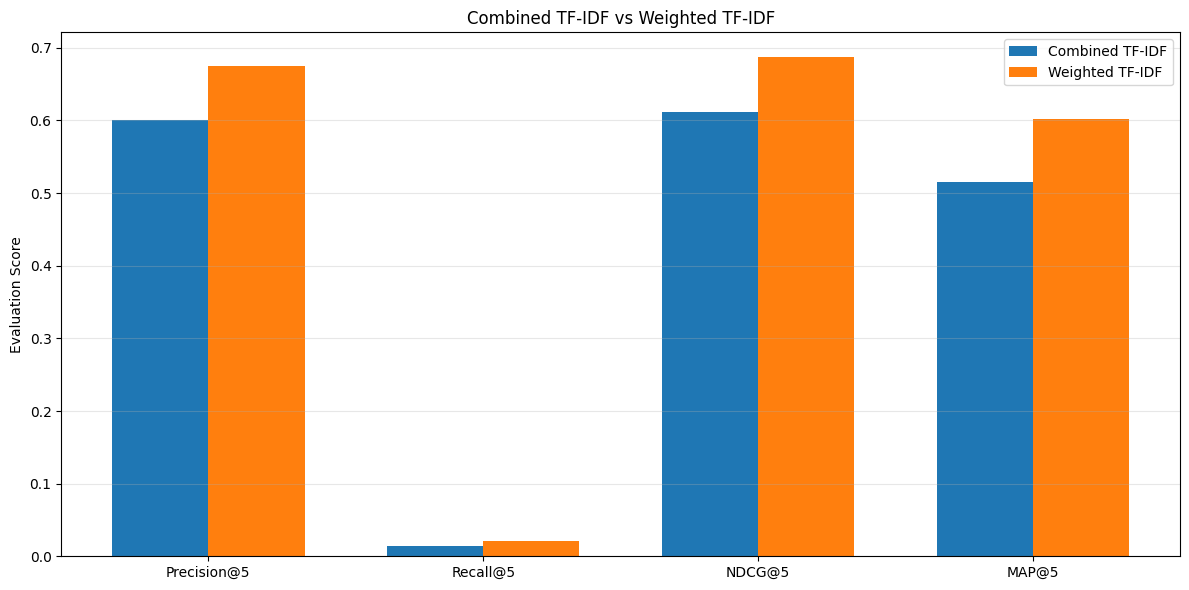

In [ ]:
plt.figure(figsize=(12, 6))

x = np.arange(len(comparison_df['Metric']))
width = 0.35

plt.bar(
    x - width/2,
    comparison_df['Combined TF-IDF'],
    width,
    label='Combined TF-IDF'
)

plt.bar(
    x + width/2,
    comparison_df['Weighted TF-IDF'],
    width,
    label='Weighted TF-IDF'
)

plt.xticks(x, comparison_df['Metric'])
plt.ylabel('Evaluation Score')
plt.title('Combined TF-IDF vs Weighted TF-IDF')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, 'model_performance_comparison.png'),
    dpi=300
)

plt.show()